# Exercício 1 - GAN para representar um paraboloide

A ideia aqui é manter o código mais linear, mostrando o passo a passo do experimento. A GAN continua sendo treinada apenas com o conjunto de pontos `D` em `R³`, sem usar pares supervisionados `z -> S(z)` no treino.

## 1. Bibliotecas

In [53]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

## 2. Paraboloide e dataset

A superfície é dada por:

`S(x1, x2) = (x1, x2, x1² + x2² + 1)`

In [54]:
def S(x):
    x1 = x[:, 0]
    x2 = x[:, 1]
    z = x1**2 + x2**2 + 1
    return torch.stack([x1, x2, z], dim=1)

In [55]:
# Número de pontos usados no dataset
N = 10000

# Pontos no domínio [-2, 2] x [-2, 2]
X = -2 + 4 * torch.rand(N, 2)

# Pontos reais no paraboloide em R³
D = S(X)

print("Shape de X:", X.shape)
print("Shape de D:", D.shape)
print("Primeiros pontos de D:")
print(D[:5])

Shape de X: torch.Size([10000, 2])
Shape de D: torch.Size([10000, 3])
Primeiros pontos de D:
tensor([[-1.7062,  0.6581,  4.3441],
        [-0.5831, -1.6123,  3.9395],
        [-1.1766, -0.7104,  2.8889],
        [ 1.3353,  0.3177,  2.8840],
        [-1.2040,  1.0627,  3.5788]])


## 3. Separação treino/teste e normalização

A normalização ajuda porque as coordenadas têm escalas diferentes: `x1` e `x2` ficam em `[-2, 2]`, enquanto a coordenada `z` fica aproximadamente entre `1` e `9`.

In [56]:
# Embaralha os índices e separa 80% treino / 20% teste
perm = torch.randperm(N)
train_size = int(0.8 * N)
train_idx = perm[:train_size]
test_idx = perm[train_size:]

D_train = D[train_idx]
D_test = D[test_idx]


dataset = TensorDataset(D_train)
loader = DataLoader(dataset, batch_size=128, shuffle=True, drop_last=True)

print("Shape de D_train:", D_train.shape)
print("Shape de D_test:", D_test.shape)

Shape de D_train: torch.Size([8000, 3])
Shape de D_test: torch.Size([2000, 3])


## 4. Gerador e crítico

Para melhorar a estabilidade do treinamento, o modelo abaixo usa uma WGAN-GP. Nesse caso o discriminador é chamado de **crítico**: ele não usa `Sigmoid` e não produz probabilidade, mas uma pontuação real.

In [57]:
class Generator(nn.Module):
    def __init__(self, latent_dim=2, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 3),
        )

    def forward(self, z):
        return self.net(z)


class Critic(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        return self.net(x)

In [58]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

latent_dim = 2
G = Generator(latent_dim=latent_dim).to(device)
C = Critic(input_dim=3).to(device)

opt_G = torch.optim.Adam(G.parameters(), lr=1e-4, betas=(0.0, 0.9))
opt_C = torch.optim.Adam(C.parameters(), lr=1e-4, betas=(0.0, 0.9))

print("Device:", device)
print(G)
print(C)

Device: cpu
Generator(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=3, bias=True)
  )
)
Critic(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=128, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)


## 5. Treinamento adversarial

Aqui o treino fica explícito no notebook. O crítico é atualizado algumas vezes antes do gerador. Isso normalmente evita que o gerador receba um sinal ruim logo no começo do treinamento.

A perda do crítico é:

`E[C(fake)] - E[C(real)] + lambda_gp * gradient_penalty`

A perda do gerador é:

`-E[C(fake)]`

In [59]:
epochs = 300
critic_steps = 5
lambda_gp = 10.0
z_min, z_max = -2.0, 2.0

history_C = []
history_G = []
history_W = []
history_GP = []

for epoch in range(epochs):
    total_loss_C = 0.0
    total_loss_G = 0.0
    total_wasserstein = 0.0
    total_gp = 0.0

    for batch in loader:
        real_points = batch[0].to(device)
        batch_size = real_points.shape[0]

        # 1) Atualiza o crítico algumas vezes
        for _ in range(critic_steps):
            z = z_min + (z_max - z_min) * torch.rand(batch_size, latent_dim, device=device)
            fake_points = G(z).detach()

            score_real = C(real_points)
            score_fake = C(fake_points)

            # Gradient penalty da WGAN-GP
            eps = torch.rand(batch_size, 1, device=device)
            eps = eps.expand_as(real_points)
            interpolated = eps * real_points + (1 - eps) * fake_points
            interpolated.requires_grad_(True)

            score_interpolated = C(interpolated)
            gradients = torch.autograd.grad(
                outputs=score_interpolated,
                inputs=interpolated,
                grad_outputs=torch.ones_like(score_interpolated),
                create_graph=True,
                retain_graph=True,
                only_inputs=True,
            )[0]

            grad_norm = gradients.view(batch_size, -1).norm(2, dim=1)
            gradient_penalty = ((grad_norm - 1) ** 2).mean()

            wasserstein_estimate = score_real.mean() - score_fake.mean()
            loss_C = score_fake.mean() - score_real.mean() + lambda_gp * gradient_penalty

            opt_C.zero_grad()
            loss_C.backward()
            opt_C.step()

        # 2) Atualiza o gerador uma vez
        z = z_min + (z_max - z_min) * torch.rand(batch_size, latent_dim, device=device)
        fake_points = G(z)
        loss_G = -C(fake_points).mean()

        opt_G.zero_grad()
        loss_G.backward()
        opt_G.step()

        total_loss_C += loss_C.item()
        total_loss_G += loss_G.item()
        total_wasserstein += wasserstein_estimate.item()
        total_gp += gradient_penalty.item()

    mean_loss_C = total_loss_C / len(loader)
    mean_loss_G = total_loss_G / len(loader)
    mean_wasserstein = total_wasserstein / len(loader)
    mean_gp = total_gp / len(loader)

    history_C.append(mean_loss_C)
    history_G.append(mean_loss_G)
    history_W.append(mean_wasserstein)
    history_GP.append(mean_gp)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}] | "
            f"Loss C: {mean_loss_C:.4f} | "
            f"Loss G: {mean_loss_G:.4f} | "
            f"W-dist: {mean_wasserstein:.4f} | "
            f"GP: {mean_gp:.4f}"
        )

Epoch [20/300] | Loss C: 0.1172 | Loss G: -0.5160 | W-dist: 0.1083 | GP: 0.0226


KeyboardInterrupt: 

## 6. Curvas de treinamento

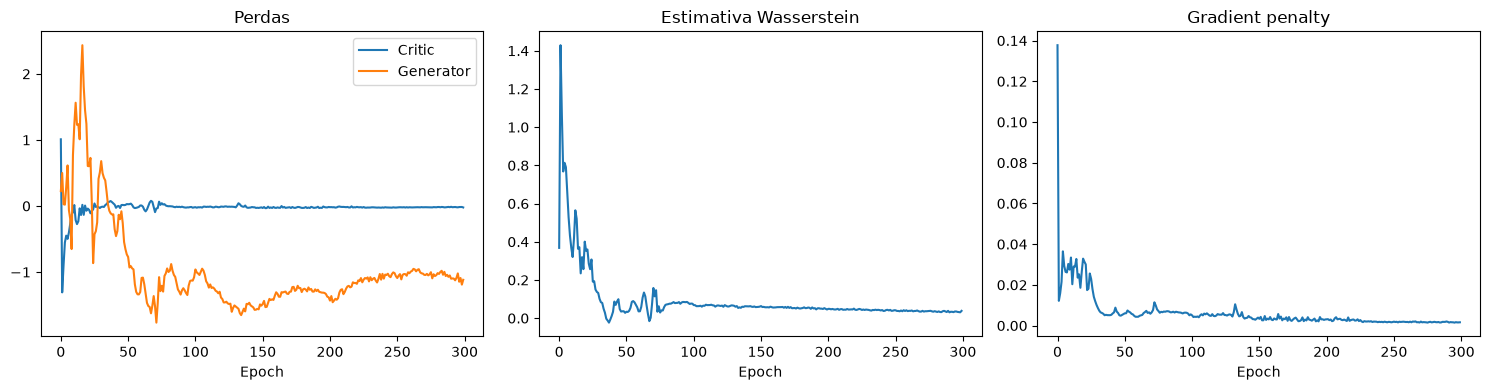

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].plot(history_C, label="Critic")
ax[0].plot(history_G, label="Generator")
ax[0].set_title("Perdas")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(history_W)
ax[1].set_title("Estimativa Wasserstein")
ax[1].set_xlabel("Epoch")

ax[2].plot(history_GP)
ax[2].set_title("Gradient penalty")
ax[2].set_xlabel("Epoch")

plt.tight_layout()
plt.show()

## 7. Avaliação do gerador

A comparação `G(z)` versus `S(z)` mede se o gerador aprendeu a mesma parametrização. Já o erro geométrico mede se os pontos gerados pertencem ao paraboloide, independentemente da parametrização.

In [48]:
G.eval()

N_test = 5000
Z = z_min + (z_max - z_min) * torch.rand(N_test, latent_dim, device=device)

with torch.no_grad():
    Y_true = S(Z).to(device)

    # O gerador produz pontos normalizados. Aqui voltamos para a escala original.
    Y_pred_norm = G(Z)
    Y_pred = Y_pred_norm * D_std.to(device) + D_mean.to(device)

error = Y_pred - Y_true

mae = torch.mean(torch.abs(error))
rmse = torch.sqrt(torch.mean(error**2))
mae_per_coord = torch.mean(torch.abs(error), dim=0)
rmse_per_coord = torch.sqrt(torch.mean(error**2, dim=0))

surface_error = Y_pred[:, 2] - Y_pred[:, 0]**2 - Y_pred[:, 1]**2 - 1
surface_mae = torch.mean(torch.abs(surface_error))
surface_rmse = torch.sqrt(torch.mean(surface_error**2))

print("MAE ponto a ponto:", mae.item())
print("RMSE ponto a ponto:", rmse.item())
print("MAE por coordenada [x1, x2, z]:", mae_per_coord.cpu().numpy())
print("RMSE por coordenada [x1, x2, z]:", rmse_per_coord.cpu().numpy())
print("MAE geométrico da superfície:", surface_mae.item())
print("RMSE geométrico da superfície:", surface_rmse.item())

MAE ponto a ponto: 0.964258074760437
RMSE ponto a ponto: 1.4051260948181152
MAE por coordenada [x1, x2, z]: [0.8993076 0.619534  1.3739324]
RMSE por coordenada [x1, x2, z]: [1.2827142 0.8356167 1.8919637]
MAE geométrico da superfície: 0.08751615881919861
RMSE geométrico da superfície: 0.19192643463611603


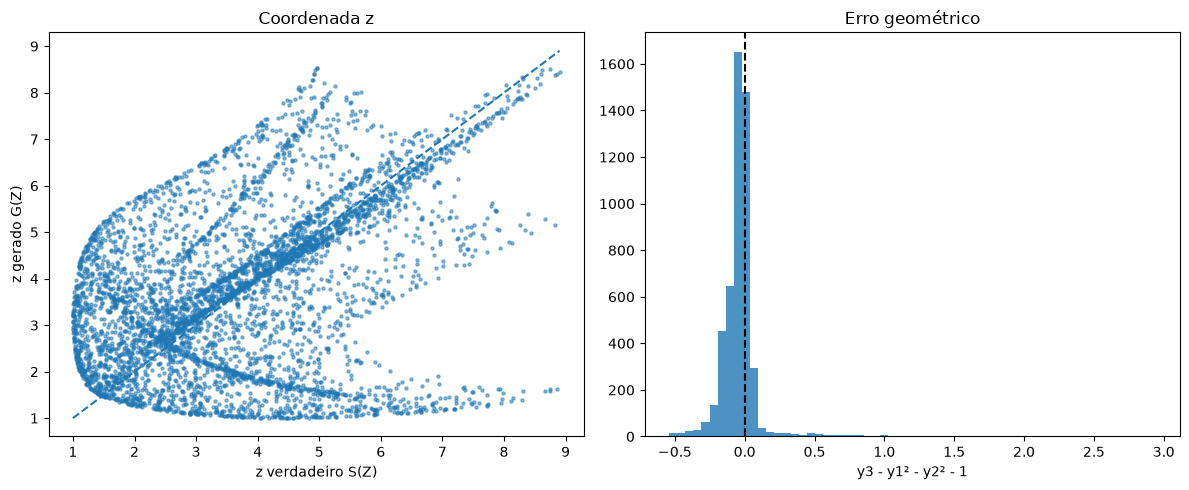

In [49]:
Y_true_cpu = Y_true.cpu()
Y_pred_cpu = Y_pred.cpu()
surface_error_cpu = surface_error.cpu()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(Y_true_cpu[:, 2], Y_pred_cpu[:, 2], s=5, alpha=0.5)
ax[0].plot(
    [Y_true_cpu[:, 2].min(), Y_true_cpu[:, 2].max()],
    [Y_true_cpu[:, 2].min(), Y_true_cpu[:, 2].max()],
    linestyle="--",
)
ax[0].set_xlabel("z verdadeiro S(Z)")
ax[0].set_ylabel("z gerado G(Z)")
ax[0].set_title("Coordenada z")

ax[1].hist(surface_error_cpu.numpy(), bins=60, alpha=0.8)
ax[1].axvline(0.0, linestyle="--", color="black")
ax[1].set_xlabel("y3 - y1² - y2² - 1")
ax[1].set_title("Erro geométrico")

plt.tight_layout()
plt.show()

## 8. Visualização do espaço latente e das coordenadas geradas

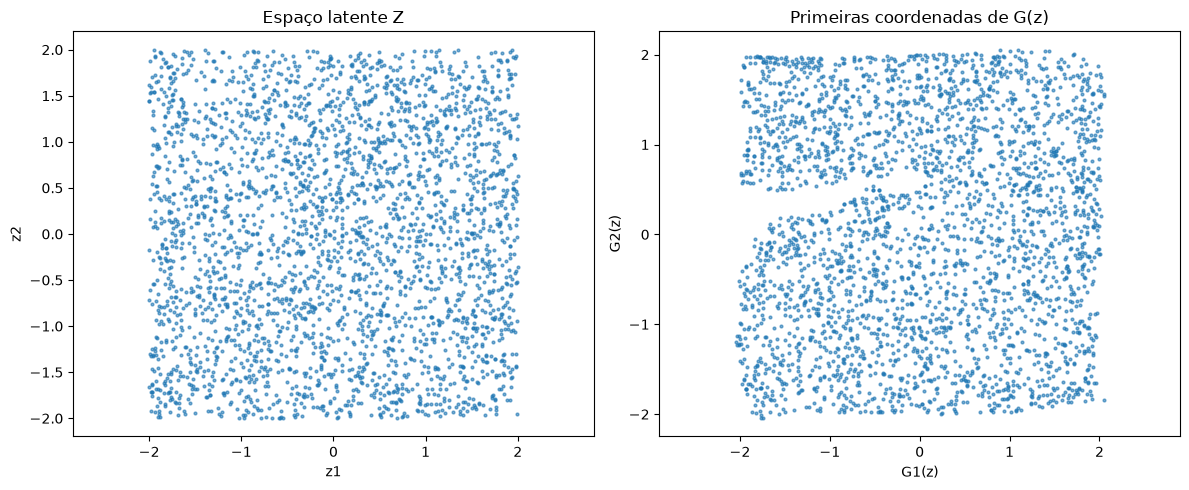

In [50]:
N_vis = 3000
Z_vis = z_min + (z_max - z_min) * torch.rand(N_vis, latent_dim, device=device)

with torch.no_grad():
    Y_vis_norm = G(Z_vis)
    Y_vis = Y_vis_norm * D_std.to(device) + D_mean.to(device)

Z_vis = Z_vis.cpu()
Y_vis = Y_vis.cpu()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(Z_vis[:, 0], Z_vis[:, 1], s=4, alpha=0.6)
ax[0].set_title("Espaço latente Z")
ax[0].set_xlabel("z1")
ax[0].set_ylabel("z2")
ax[0].axis("equal")

ax[1].scatter(Y_vis[:, 0], Y_vis[:, 1], s=4, alpha=0.6)
ax[1].set_title("Primeiras coordenadas de G(z)")
ax[1].set_xlabel("G1(z)")
ax[1].set_ylabel("G2(z)")
ax[1].axis("equal")

plt.tight_layout()
plt.show()

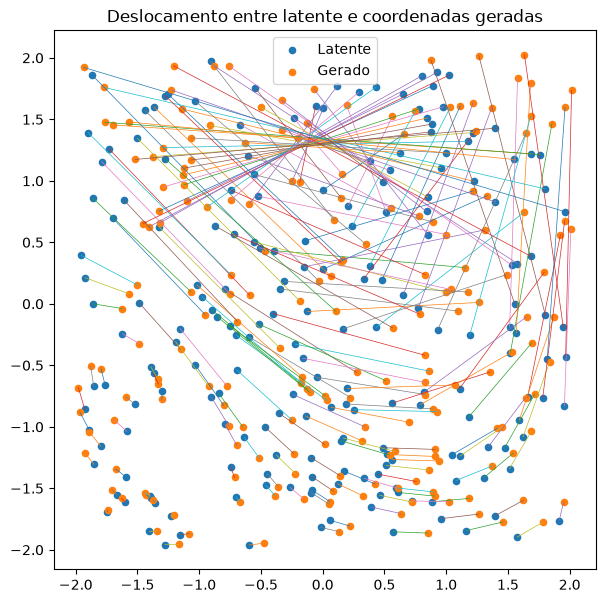

In [51]:
N_lines = 200
Z_lines = z_min + (z_max - z_min) * torch.rand(N_lines, latent_dim, device=device)

with torch.no_grad():
    Y_lines_norm = G(Z_lines)
    Y_lines = Y_lines_norm * D_std.to(device) + D_mean.to(device)

Z_lines = Z_lines.cpu()
Y_lines = Y_lines.cpu()

plt.figure(figsize=(7, 7))
plt.scatter(Z_lines[:, 0], Z_lines[:, 1], s=20, label="Latente")
plt.scatter(Y_lines[:, 0], Y_lines[:, 1], s=20, label="Gerado")

for i in range(N_lines):
    plt.plot(
        [Z_lines[i, 0], Y_lines[i, 0]],
        [Z_lines[i, 1], Y_lines[i, 1]],
        linewidth=0.5,
    )

plt.axis("equal")
plt.legend()
plt.title("Deslocamento entre latente e coordenadas geradas")
plt.show()